In [2]:
import sys
print(sys.executable)

/home/piets/sirna_shrna_offtargets/.venv/bin/python


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

print("All imports successful")

All imports successful


In [4]:
# Load TPM dataset and processed gene_mapping data from Notebook 01 to inspect targeted silencing 


norm_counts = pd.read_csv(
    "../data/raw/GSE114273 (siPARP1_siPARP2)/GSE114273_norm_counts_TPM_GRCh38.p13_NCBI.tsv.gz",
    sep="\t"
)

gene_mapping = pd.read_csv(
    "../data/processed/GSE114273 (siPARP1_siPARP2)/GSE114273_gene_mapping_protein_coding.tsv",
    sep="\t"
)

print("TPM matrix:", norm_counts.shape)
print("Gene mapping:", gene_mapping.shape)

TPM matrix: (39376, 19)
Gene mapping: (19227, 5)


In [5]:
# Link gene annotation to expression data
expression_data = gene_mapping[
    ["GeneID", "EnsemblGeneID"]
].merge(
    norm_counts,
    on="GeneID",
    how="inner"
)

display(expression_data.head().shape)

(5, 20)

In [6]:
# Select samples for downstream analysis

sample_columns = [
    "GSM3138707", "GSM3138708",
    "GSM3138709", "GSM3138710",
    "GSM3138711", "GSM3138712",
    "GSM3138713", "GSM3138714",
    "GSM3138715", "GSM3138716"
]

expression_data = expression_data[
    ["GeneID", "EnsemblGeneID"] + sample_columns
].copy()

In [7]:
# Rename sample labels

sample_labels = {
    "GSM3138707": "siNC_rep1",
    "GSM3138708": "siNC_rep2",
    "GSM3138709": "siPARP1-A_rep1",
    "GSM3138710": "siPARP1-A_rep2",
    "GSM3138711": "siPARP1-B_rep1",
    "GSM3138712": "siPARP1-B_rep2",
    "GSM3138713": "siPARP2-A_rep1",
    "GSM3138714": "siPARP2-A_rep2",
    "GSM3138715": "siPARP2-B_rep1",
    "GSM3138716": "siPARP2-B_rep2"
}

expression_data = expression_data.rename(columns=sample_labels)

display(expression_data.head())

,GeneID,EnsemblGeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
0,79501,ENSG00000186092,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,729759,ENSG00000284733,0.00000,0.00000,0.11700,0.00000,0.00000,0.00000,0.00000,0.00000,0.12570,0.00000
2,81399,ENSG00000284662,0.01957,0.03683,0.03803,0.02007,0.02057,0.02181,0.03558,0.03497,0.02042,0.03697
3,148398,ENSG00000187634,21.28000,23.77000,17.28000,15.92000,25.34000,24.84000,20.35000,18.93000,13.07000,15.33000
4,26155,ENSG00000188976,98.92000,111.50000,112.20000,109.70000,111.50000,101.90000,147.10000,139.00000,126.30000,130.80000


In [8]:
# Define experimental groups

sample_groups = {
    "siNC": ["siNC_rep1", "siNC_rep2"],
    "siPARP1-A": ["siPARP1-A_rep1", "siPARP1-A_rep2"],
    "siPARP1-B": ["siPARP1-B_rep1", "siPARP1-B_rep2"],
    "siPARP2-A": ["siPARP2-A_rep1", "siPARP2-A_rep2"],
    "siPARP2-B": ["siPARP2-B_rep1", "siPARP2-B_rep2"]
}

In [9]:
# Validate

print("Expression data shape:", expression_data.shape)
display(expression_data.head())

Expression data shape: (19227, 12)


,GeneID,EnsemblGeneID,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
0,79501,ENSG00000186092,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000,0.00000
1,729759,ENSG00000284733,0.00000,0.00000,0.11700,0.00000,0.00000,0.00000,0.00000,0.00000,0.12570,0.00000
2,81399,ENSG00000284662,0.01957,0.03683,0.03803,0.02007,0.02057,0.02181,0.03558,0.03497,0.02042,0.03697
3,148398,ENSG00000187634,21.28000,23.77000,17.28000,15.92000,25.34000,24.84000,20.35000,18.93000,13.07000,15.33000
4,26155,ENSG00000188976,98.92000,111.50000,112.20000,109.70000,111.50000,101.90000,147.10000,139.00000,126.30000,130.80000


In [ ]:
# save df

output_dir = Path(
    "../data/processed/GSE114273 (siPARP1_siPARP2)"
)

output_dir.mkdir(parents=True, exist_ok=True)

expression_data.to_csv(
    output_dir / "GSE114273_expression_data.tsv",
    sep="\t",
    index=False
)

In [26]:
# Identify target genes, PARP1 and PARP2

target_genes = gene_mapping[
    gene_mapping["Symbol"].isin(["PARP1", "PARP2"])
]

display(
    target_genes[
        ["GeneID", "EnsemblGeneID", "Symbol", "GeneType"]
    ]
)

,GeneID,EnsemblGeneID,Symbol,GeneType
1832,142,ENSG00000143799,PARP1,protein-coding
12440,10038,ENSG00000129484,PARP2,protein-coding


In [27]:
# Extract target gene Ensembl ID

parp1_id = target_genes.loc[
    target_genes["Symbol"] == "PARP1", "EnsemblGeneID"
].iloc[0]

parp2_id = target_genes.loc[
    target_genes["Symbol"] == "PARP2", "EnsemblGeneID"
].iloc[0]

print("PARP1:", parp1_id)
print("PARP2:", parp2_id)

PARP1: ENSG00000143799
PARP2: ENSG00000129484


In [28]:
# Extract target gene expression

target_expression = expression_data[
    expression_data["EnsemblGeneID"].isin([parp1_id, parp2_id])
].copy()

# Add gene symbols for easier interpretation
target_expression.insert(
    2,
    "Symbol",
    target_expression["EnsemblGeneID"].map({
        parp1_id: "PARP1",
        parp2_id: "PARP2"
    })
)

display(target_expression)

,GeneID,EnsemblGeneID,Symbol,siNC_rep1,siNC_rep2,siPARP1-A_rep1,siPARP1-A_rep2,siPARP1-B_rep1,siPARP1-B_rep2,siPARP2-A_rep1,siPARP2-A_rep2,siPARP2-B_rep1,siPARP2-B_rep2
1832,142,ENSG00000143799,PARP1,209.50,236.60,2.348,2.507,4.273,4.182,181.300,169.800,85.080,72.760
12440,10038,ENSG00000129484,PARP2,22.99,23.45,18.990,17.820,16.620,15.730,2.884,2.219,1.632,1.173


In [30]:
# Calculate group means for each gene target

# PARP1 expression means
parp1_control_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP1",
    ["siNC_rep1", "siNC_rep2"]
].mean(axis=1).iloc[0]

parp1_A_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP1",
    ["siPARP1-A_rep1", "siPARP1-A_rep2"]
].mean(axis=1).iloc[0]

parp1_B_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP1",
    ["siPARP1-B_rep1", "siPARP1-B_rep2"]
].mean(axis=1).iloc[0]


# PARP2 expression means
parp2_control_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP2",
    ["siNC_rep1", "siNC_rep2"]
].mean(axis=1).iloc[0]

parp2_A_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP2",
    ["siPARP2-A_rep1", "siPARP2-A_rep2"]
].mean(axis=1).iloc[0]

parp2_B_mean = target_expression.loc[
    target_expression["Symbol"] == "PARP2",
    ["siPARP2-B_rep1", "siPARP2-B_rep2"]
].mean(axis=1).iloc[0]

In [32]:
# Calculate fold changes
parp1_A_fc = parp1_A_mean / parp1_control_mean
parp1_B_fc = parp1_B_mean / parp1_control_mean

parp2_A_fc = parp2_A_mean / parp2_control_mean
parp2_B_fc = parp2_B_mean / parp2_control_mean


# Summarise results
knockdown_summary = pd.DataFrame({
    "Target": ["PARP1", "PARP1", "PARP2", "PARP2"],
    "siRNA": ["siPARP1-A", "siPARP1-B", "siPARP2-A", "siPARP2-B"],
    "Control_mean_TPM": [
        parp1_control_mean, parp1_control_mean,
        parp2_control_mean, parp2_control_mean
    ],
    "Treated_mean_TPM": [
        parp1_A_mean, parp1_B_mean,
        parp2_A_mean, parp2_B_mean
    ],
    "Fold_change": [
        parp1_A_fc, parp1_B_fc,
        parp2_A_fc, parp2_B_fc
    ]
})

knockdown_summary["log2FC"] = np.log2(
    knockdown_summary["Fold_change"]
)

knockdown_summary["Knockdown_%"] = (
    1 - knockdown_summary["Fold_change"]
) * 100

display(knockdown_summary.round(3))

,Target,siRNA,Control_mean_TPM,Treated_mean_TPM,Fold_change,log2FC,Knockdown_%
0,PARP1,siPARP1-A,223.05,2.428,0.011,-6.522,98.912
1,PARP1,siPARP1-B,223.05,4.228,0.019,-5.721,98.105
2,PARP2,siPARP2-A,23.22,2.552,0.110,-3.186,89.012
3,PARP2,siPARP2-B,23.22,1.402,0.060,-4.049,93.960


In [33]:
# Convert expression data to long format

expression_long = target_expression.melt(
    id_vars=["GeneID", "EnsemblGeneID", "Symbol"],
    value_vars=[
        sample
        for samples in sample_groups.values()
        for sample in samples
    ],
    var_name="Sample",
    value_name="TPM"
)

# Assign experimental group to each sample
sample_to_group = {
    sample: group
    for group, samples in sample_groups.items()
    for sample in samples
}

expression_long["Group"] = expression_long["Sample"].map(sample_to_group)

display(expression_long)

,GeneID,EnsemblGeneID,Symbol,Sample,TPM,Group
0,142,ENSG00000143799,PARP1,siNC_rep1,209.500,siNC
1,10038,ENSG00000129484,PARP2,siNC_rep1,22.990,siNC
2,142,ENSG00000143799,PARP1,siNC_rep2,236.600,siNC
3,10038,ENSG00000129484,PARP2,siNC_rep2,23.450,siNC
4,142,ENSG00000143799,PARP1,siPARP1-A_rep1,2.348,siPARP1-A
5,10038,ENSG00000129484,PARP2,siPARP1-A_rep1,18.990,siPARP1-A
6,142,ENSG00000143799,PARP1,siPARP1-A_rep2,2.507,siPARP1-A
7,10038,ENSG00000129484,PARP2,siPARP1-A_rep2,17.820,siPARP1-A
8,142,ENSG00000143799,PARP1,siPARP1-B_rep1,4.273,siPARP1-B
9,10038,ENSG00000129484,PARP2,siPARP1-B_rep1,16.620,siPARP1-B


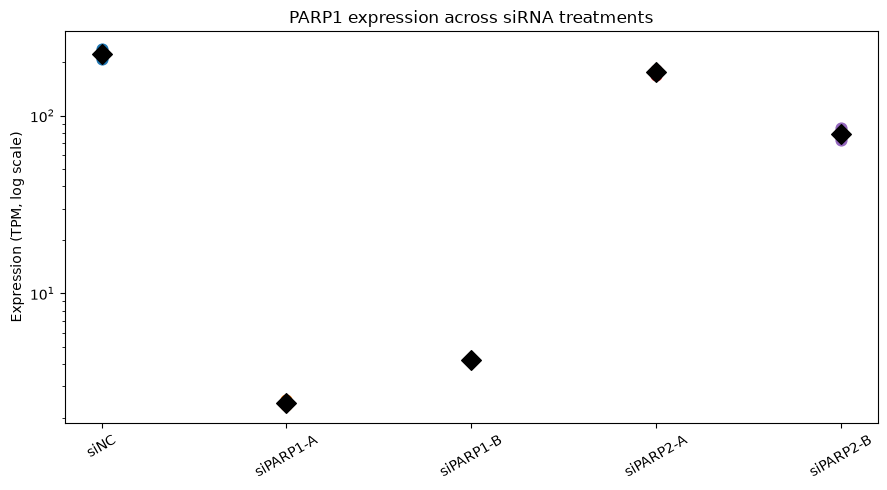

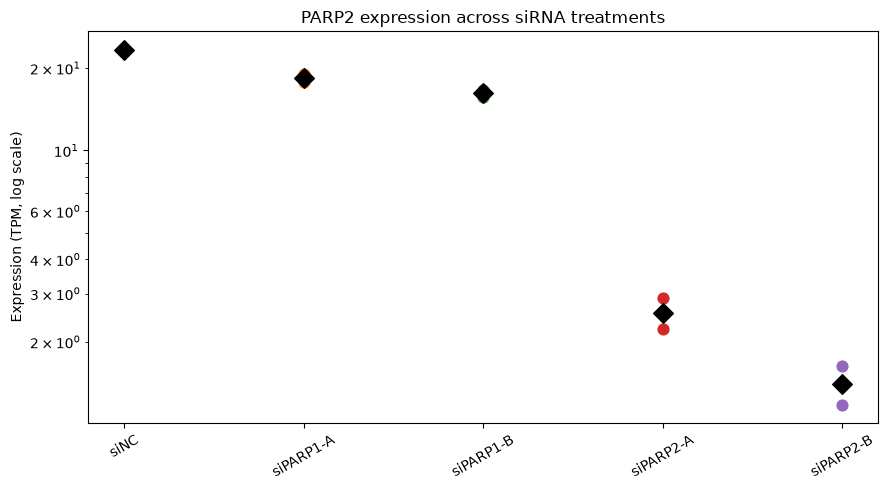

In [35]:
# Plot target gene expression on a logarithmic scale

for gene in ["PARP1", "PARP2"]:

    gene_data = expression_long[
        expression_long["Symbol"] == gene
    ]

    groups = list(sample_groups.keys())

    fig, ax = plt.subplots(figsize=(9, 5))

    for i, group in enumerate(groups):

        group_data = gene_data[
            gene_data["Group"] == group
        ]["TPM"]

        # Individual replicates
        ax.scatter(
            [i] * len(group_data),
            group_data,
            s=60,
            zorder=2
        )

        # Group mean
        ax.scatter(
            i,
            group_data.mean(),
            marker="D",
            s=100,
            color="black",
            zorder=3
        )

    ax.set_yscale("log")
    ax.set_xticks(range(len(groups)))
    ax.set_xticklabels(groups, rotation=30)
    ax.set_ylabel("Expression (TPM, log scale)")
    ax.set_title(f"{gene} expression across siRNA treatments")

    plt.tight_layout()
    plt.show()

In [36]:
from scipy.stats import ttest_ind

# Perform exploratory Welch's t-tests

statistical_results = []

for gene in ["PARP1", "PARP2"]:

    gene_data = target_expression[
        target_expression["Symbol"] == gene
    ]

    control_values = gene_data[
        sample_groups["siNC"]
    ].values.flatten()

    for group in sample_groups:

        if group == "siNC":
            continue

        treated_values = gene_data[
            sample_groups[group]
        ].values.flatten()

        test = ttest_ind(
            control_values,
            treated_values,
            equal_var=False
        )

        statistical_results.append({
            "Target": gene,
            "Treatment": group,
            "Control_mean_TPM": control_values.mean(),
            "Treated_mean_TPM": treated_values.mean(),
            "t_statistic": test.statistic,
            "p_value": test.pvalue
        })

statistical_results = pd.DataFrame(statistical_results)

display(statistical_results.round(4))

,Target,Treatment,Control_mean_TPM,Treated_mean_TPM,t_statistic,p_value
0,PARP1,siPARP1-A,223.05,2.4275,16.2818,0.0390
1,PARP1,siPARP1-B,223.05,4.2275,16.1492,0.0394
2,PARP1,siPARP2-A,223.05,175.5500,3.2270,0.1373
3,PARP1,siPARP2-B,223.05,78.9200,9.6832,0.0300
4,PARP2,siPARP1-A,23.22,18.4050,7.6600,0.0485
5,PARP2,siPARP1-B,23.22,16.1750,14.0640,0.0143
6,PARP2,siPARP2-A,23.22,2.5515,51.1220,0.0008
7,PARP2,siPARP2-B,23.22,1.4025,67.1482,0.0002


In [37]:
# Save Notebook 02 results

output_dir = Path(
    "../data/processed/GSE114273 (siPARP1_siPARP2)"
)

output_dir.mkdir(parents=True, exist_ok=True)

target_expression.to_csv(
    output_dir / "GSE114273_target_expression.tsv",
    sep="\t",
    index=False
)

knockdown_summary.to_csv(
    output_dir / "GSE114273_knockdown_summary.tsv",
    sep="\t",
    index=False
)

statistical_results.to_csv(
    output_dir / "GSE114273_on_target_statistics.tsv",
    sep="\t",
    index=False
)

print("Notebook 02 results saved.")

Notebook 02 results saved.


#### Summary — On-target analysis

The on-target analysis evaluated four siRNAs targeting PARP1 and PARP2 using normalized RNA-seq expression data (TPM).

All four siRNAs showed substantial reductions in their intended target:

| siRNA | Target | Estimated knockdown |
|---|---|---:|
| siPARP1-A | PARP1 | 98.9% |
| siPARP1-B | PARP1 | 98.1% |
| siPARP2-A | PARP2 | 89.0% |
| siPARP2-B | PARP2 | 93.9% |

The results are descriptive estimates based on two biological replicates per group. Exploratory statistical comparisons were performed, but the limited replication restricts the strength of statistical conclusions.